# 🚦 Auditoría Exploratoria del Tráfico Urbano de Madrid y Cruce Espacial con Paradas EMT

En este cuaderno se audita la fuente dinámica de **Tráfico en Tiempo Real del Ayuntamiento de Madrid** (`informo.madrid.es`, **4.904 puntos de medida**), paso previo imprescindible para construir el **Modelo 2 (*Contexto Vial: GTFS + Tráfico Urbano*)**.

Los objetivos analíticos de este cuaderno son:
1. **Auditar la calidad y fiabilidad del dato bruto:** Identificar sensores averiados (`error_sensor != 'N'`), valores centinela negativos (`-1`), duplicados y coordenadas atípicas.

2. **Analizar el cruce espacial con la red EMT:** Vincular geodésicamente cada una de las **4.928 paradas de autobús** (`stops_limpio.csv`) con los sensores operativos más próximos para evaluar la cobertura real en el interior de la **M-30** y en la periferia.

3. **Definir las reglas de saneamiento y *Feature Engineering* espacial** que pasarán a producción en `src/sensores_trafico.py`.

In [1]:
import os
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.4})
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})

RUTA_TRAFICO = Path('../data/raw/sensores_trafico/sensores.csv')
RUTA_STOPS = Path('../data/processed/stops_limpio.csv')

assert RUTA_TRAFICO.exists(), f"No se encuentra {RUTA_TRAFICO}"
assert RUTA_STOPS.exists(), f"No se encuentra {RUTA_STOPS}"

df_trafico = pd.read_csv(RUTA_TRAFICO, dtype={'idelem': str})
df_stops = pd.read_csv(RUTA_STOPS, dtype={'stop_id': str})

print("====== EXPLORACIÓN INICIAL: TRÁFICO EN TIEMPO REAL (AYUNTAMIENTO DE MADRID) ======\n")
print(f"-> Timestamp de la captura   : {df_trafico['timestamp_feed'].iloc[0]}")
print(f"-> Dimensiones brutas        : {df_trafico.shape[0]:,} sensores x {df_trafico.shape[1]} columnas")
print(f"-> Paradas EMT de referencia : {len(df_stops):,} postes activos")
print("\n-> Tipos de dato inferidos:")
print(df_trafico.dtypes)

====== EXPLORACIÓN INICIAL: TRÁFICO EN TIEMPO REAL (AYUNTAMIENTO DE MADRID) ======

-> Timestamp de la captura   : 17/11/2026 21:50:02
-> Dimensiones brutas        : 4,904 sensores x 14 columnas
-> Paradas EMT de referencia : 4,934 postes activos

-> Tipos de dato inferidos:
timestamp_feed           str
idelem                   str
descripcion              str
acceso_asociado      float64
intensidad             int64
ocupacion              int64
carga                  int64
nivel_servicio         int64
intensidad_sat       float64
velocidad_trafico    float64
error_sensor             str
subarea              float64
lat                  float64
lon                  float64
dtype: object


### Estructura y Dimensionalidad Inicial: 
El boletín oficial de tráfico en tiempo real (`sensores.csv`, instantánea del `17/11/2026 21:50:02`) consta de **4.904 registros** (puntos de medida municipales) y **14 variables**: **3 campos de texto (`str`)** correspondientes a marca temporal, identificador y descripción vial (`timestamp_feed`, `idelem`, `descripcion`, más `error_sensor` como bandera de estado —4 en total—), **4 variables enteras (`int64`)** de medición continua sin nulos (`intensidad`, `ocupacion`, `carga`, `nivel_servicio`) y **6 variables decimales (`float64`)** que agrupan las coordenadas geográficas (`lat`, `lon`) junto con campos con presencia de valores ausentes (`acceso_asociado`, `intensidad_sat`, `velocidad_trafico`, `subarea`). Esta malla sensorial sirve de base para su cruce geodésico contra los **4.928 postes activos** de la red EMT (`stops_limpio.csv`).

### 📋 Diccionario de Datos del Feed de Tráfico (`sensores.csv`)

Este notebook utiliza el diccionario de datos definido para el conjunto `sensores`.  

El documento completo se encuentra en:

👉 [`../docs/10_sensores_trafico_Dict.md`](../docs/10_sensores_trafico_Dict.md)

| Bloque | Variable | Tipo | Descripción Operativa |
| :--- | :--- | :--- | :--- |
| **Feed Bruto** | `timestamp_feed` | `String` | Fecha y hora oficial de publicación del boletín XML del Ayuntamiento. |
| **Feed Bruto** | `idelem` | `String` | Identificador único del punto de medida (espira electromagnética / estación). |
| **Feed Bruto** | `descripcion` | `String` | Ubicación vial descriptiva del sensor en el callejero de Madrid. |
| **Feed Bruto** | `acceso_asociado` | `String` | Código del eje o enlace viario asociado (especialmente en M-30). |
| **Feed Bruto** | `intensidad` | `Float64` | Flujo vehicular medido en vehículos por hora (`veh/h`). |
| **Feed Bruto** | `ocupacion` | `Float64` | Porcentaje de tiempo (`0–100%`) que el sensor permanece ocupado por vehículos. |
| **Feed Bruto** | `carga` | `Float64` | Grado de saturación vial (`0–126%`) estimado por el Centro de Gestión de Movilidad. |
| **Feed Bruto** | `nivel_servicio` | `Float64` | Indicador discreto de fluidez (`0`: Fluido, `1`: Lento, `2`: Retenciones, `3`: Congestionado). |
| **Feed Bruto** | `intensidad_sat` | `Float64` | Capacidad máxima teórica (`veh/h`) de la vía donde se ubica el sensor. |
| **Feed Bruto** | `velocidad_trafico` | `Float64` | Velocidad media medida en km/h (disponible principalmente en túneles y M-30). |
| **Feed Bruto** | `error_sensor` | `String` | Bandera de estado técnico (`'N'` = Operativo normal; `'S'` / `'E'` = Incidencia o sin dato). |
| **Feed Bruto** | `subarea` | `String` | Código de sector de regulación semafórica de Madrid. |
| **Feed Bruto** | `lat`, `lon` | `Float64` | Coordenadas geográficas transformadas desde `EPSG:25830` a `WGS84` (`EPSG:4326`). |
| **Cruce Espacial EMT** | `distancia_sensor_mas_cercano_m` | `Float64` | Distancia geodésica en metros desde la parada EMT hasta el sensor operativo más próximo. |
| **Cruce Espacial EMT** | `num_sensores_500m` | `Int64` | Número total de sensores operativos ubicados dentro del radio principal de 500 metros. |
| **Cruce Espacial EMT** | `tiene_cobertura_trafico_500m` | `Boolean` | Indicador de cobertura directa (`True` si hay ≥ 1 sensor a ≤ 500 m; `False` si usa respaldo ≤ 1.000 m). |
| **Cruce Espacial EMT** | `trafico_carga_entorno` | `Float64` | Saturación vial media ponderada por inversa de la distancia (*IDW*, `0–126%`) alrededor de la parada. |
| **Cruce Espacial EMT** | `trafico_ocupacion_entorno` | `Float64` | Porcentaje medio ponderado (*IDW*, `0–100%`) de ocupación del carril en el entorno de la parada. |
| **Cruce Espacial EMT** | `trafico_intensidad_entorno` | `Float64` | Flujo vehicular medio ponderado (*IDW*, `veh/h`) en el entorno inmediato de la parada. |
| **Cruce Espacial EMT** | `trafico_nivel_servicio_max` | `Float64` | Peor nivel de servicio semafórico (`0` a `3`) registrado dentro del radio operativo de la parada. |
| **Cruce Espacial EMT** | `trafico_regimen` | `String` | Régimen de tráfico categórico del entorno (`"Fluido"`, `"Saturado_Con_Movimiento"`, `"Colapso_Estatico"`, `"Libre"`). |
| **Cruce Espacial EMT** | `trafico_indice_friccion` | `Float64` | Índice de fricción vial ponderado (`(Ocupación × Carga) / max(Intensidad, 1)`). |
| **Cruce Espacial EMT** | `trafico_presion_entorno` | `Float64` | Presión de congestión ponderada con decaimiento espacial reforzado a corto alcance ($\le 250\text{ m}$). |

### 1. Auditoría de Calidad: Nulos, Duplicados, Estado Técnico y Outliers Físicos

Se inspecciona la integridad de los **4.904 sensores** capturados para detectar estaciones fuera de servicio (`error_sensor != 'N'`), valores centinela negativos (`-1`), registros duplicados y posibles coordenadas fuera del término municipal de Madrid.

In [2]:
print("====== AUDITORÍA DE CALIDAD: TRÁFICO EN TIEMPO REAL ======\n")

# 1. Nulos por columna
print("1. CONTEO DE VALORES NULOS:")
nulos = df_trafico.isnull().sum()
for col, cnt in nulos.items():
    print(f"   - {col:<20}: {cnt:>5,} nulos ({cnt/len(df_trafico)*100:.2f}%)")

# 2. Duplicados
dup_exactos = df_trafico.duplicated().sum()
dup_idelem = df_trafico['idelem'].duplicated().sum()
print(f"\n2. CONTROL DE DUPLICADOS:")
print(f"   - Filas 100% idénticas     : {dup_exactos:,}")
print(f"   - IDs de sensor duplicados : {dup_idelem:,}")

# 3. Estado técnico del sensor (error_sensor)
print(f"\n3. ESTADO TÉCNICO DE LOS SENSORES (error_sensor):")
print(df_trafico['error_sensor'].value_counts(dropna=False).to_string())

# 4. Valores centinela negativos (< 0) y outliers físicos
print("\n4. VALORES CENTINELA NEGATIVOS (< 0) Y RANGOS FÍSICOS:")
vars_medida = ['intensidad', 'ocupacion', 'carga', 'nivel_servicio', 'velocidad_trafico']
for v in vars_medida:
    negativos = (df_trafico[v] < 0).sum()
    validos = df_trafico[df_trafico[v] >= 0][v]
    v_min = validos.min() if len(validos) > 0 else np.nan
    v_max = validos.max() if len(validos) > 0 else np.nan
    print(f"   - {v:<20}: {negativos:>4,} negativos (<0) | Rango válido: [{v_min} .. {v_max}]")

# 5. Control de coordenadas geográficas dentro del área metropolitana de Madrid
fuera_madrid = df_trafico[
    (df_trafico['lat'] < 40.30) | (df_trafico['lat'] > 40.55) |
    (df_trafico['lon'] < -3.85) | (df_trafico['lon'] > -3.50) |
    (df_trafico['lat'].isnull())
]
print(f"\n5. CONTROL GEOESPACIAL (WGS84 MADRID):")
print(f"   - Sensores con coordenadas nulas o fuera de Madrid: {len(fuera_madrid):,}")


====== AUDITORÍA DE CALIDAD: TRÁFICO EN TIEMPO REAL ======

1. CONTEO DE VALORES NULOS:
   - timestamp_feed      :     0 nulos (0.00%)
   - idelem              :     0 nulos (0.00%)
   - descripcion         :    57 nulos (1.16%)
   - acceso_asociado     :   735 nulos (14.99%)
   - intensidad          :     0 nulos (0.00%)
   - ocupacion           :     0 nulos (0.00%)
   - carga               :     0 nulos (0.00%)
   - nivel_servicio      :     0 nulos (0.00%)
   - intensidad_sat      :   311 nulos (6.34%)
   - velocidad_trafico   : 4,593 nulos (93.66%)
   - error_sensor        :    57 nulos (1.16%)
   - subarea             :   311 nulos (6.34%)
   - lat                 :     0 nulos (0.00%)
   - lon                 :     0 nulos (0.00%)

2. CONTROL DE DUPLICADOS:
   - Filas 100% idénticas     : 0
   - IDs de sensor duplicados : 0

3. ESTADO TÉCNICO DE LOS SENSORES (error_sensor):
error_sensor
N      4362
S       485
NaN      57

4. VALORES CENTINELA NEGATIVOS (< 0) Y RANGOS FÍSICOS:
 

> **📌 Diagnóstico de Calidad del Feed de Tráfico:**
> * **Filtrado Técnico Obligatorio:** De los **4.904 puntos de medida**, únicamente **4.362 (`88,95%`)** operan en estado normal (`error_sensor == 'N'`). Los **542 sensores restantes** (`485` en estado `'S'` y `57` con estado/descripción nulos) deben excluirse antes del cruce espacial para evitar asignar lecturas corruptas a las paradas de autobús.
>
> * **Saneamiento de Centinelas y Selección de Métricas:** Se detectan valores negativos (`-1`) en `intensidad`, `ocupacion`, `carga` y `nivel_servicio` que corresponden a lecturas inválidas. Asimismo, dado que `velocidad_trafico` presenta un **93,66% de valores nulos** (restringida casi exclusivamente a túneles de la M-30), las métricas universales para toda la superficie urbana son **`intensidad`**, **`ocupacion`**, **`carga`** (donde valores > 100 representan sobresaturación real) y **`nivel_servicio`**.


### 2. Análisis de Sensibilidad Espacial e Ingeniería de Características (*IDW 500 m*)

#### 2.1. Evaluación del Radio de Cobertura Óptimo (`150 m` a `1.000 m`)

Se evalúa el compromiso entre precisión local y cobertura territorial midiendo qué porcentaje de las **4.928 paradas EMT** (segmentadas entre Interior M-30 y Periferia Exterior) dispone de al menos un sensor operativo dentro de distintos radios geodésicos candidatos.

In [3]:
print("====== ANÁLISIS DE SENSIBILIDAD: RADIO DE COBERTURA ESPACIAL ======\n")

# 1. Filtrado de sensores operativos
df_sensores_limpio = df_trafico[df_trafico['error_sensor'] == 'N'].copy()

# 2. Matriz de distancias geodésicas (Haversine) entre 4.928 paradas y 4.362 sensores
R_TIERRA_M = 6371000.0
lat_stops = np.radians(df_stops['stop_lat'].values)[:, np.newaxis]
lon_stops = np.radians(df_stops['stop_lon'].values)[:, np.newaxis]
lat_sens = np.radians(df_sensores_limpio['lat'].values)[np.newaxis, :]
lon_sens = np.radians(df_sensores_limpio['lon'].values)[np.newaxis, :]

dlat = lat_sens - lat_stops
dlon = lon_sens - lon_stops
a = np.sin(dlat / 2.0) ** 2 + np.cos(lat_stops) * np.cos(lat_sens) * np.sin(dlon / 2.0) ** 2
matriz_dist_m = 2.0 * R_TIERRA_M * np.arcsin(np.sqrt(a))

# 3. Evaluación comparativa para distintos radios candidatos
radios_prueba = [150, 300, 500, 750, 1000]
resumen_radios = []

es_m30 = df_stops['en_alta_densidad_real'].values

for r in radios_prueba:
    cubierta = (matriz_dist_m <= r).any(axis=1)
    sensores_en_radio = (matriz_dist_m <= r).sum(axis=1)

    resumen_radios.append({
        'Radio (m)': r,
        'Cobertura Global (%)': round(cubierta.mean() * 100, 2),
        'Cobertura Interior M-30 (%)': round(cubierta[es_m30].mean() * 100, 2),
        'Cobertura Periferia (%)': round(cubierta[~es_m30].mean() * 100, 2),
        'Media Sensores / Parada': round(sensores_en_radio.mean(), 2)
    })

df_sensibilidad = pd.DataFrame(resumen_radios)
print(df_sensibilidad.to_string(index=False))


====== ANÁLISIS DE SENSIBILIDAD: RADIO DE COBERTURA ESPACIAL ======

 Radio (m)  Cobertura Global (%)  Cobertura Interior M-30 (%)  Cobertura Periferia (%)  Media Sensores / Parada
       150                 68.97                        88.21                    59.71                     2.50
       300                 84.86                        98.00                    78.53                     7.46
       500                 93.29                        99.81                    90.15                    18.43
       750                 96.51                       100.00                    94.84                    38.74
      1000                 98.07                       100.00                    97.15                    66.56


> **📌 Selección del Radio Operativo (`500 m` IDW + Respaldo `1.000 m`):** El radio de **500 metros** constituye el punto óptimo de equilibrio al cubrir el **93,28%** de toda la red (**99,81%** en el interior de la M-30 y **90,15%** en la periferia) con un promedio de **18,43 sensores** por parada. Mediante ponderación por inversa de la distancia (*Inverse Distance Weighting*, *IDW*), los sensores más cercanos al poste reciben un peso dominante, mientras que para el **6,72%** de paradas periféricas aisladas se habilita un respaldo hasta **1.000 metros** señalizado mediante el indicador booleano `tiene_cobertura_trafico_500m`.

#### 2.2. Saneamiento y Cruce Geodésico Ponderado (*IDW 500 m* + Respaldo *1.000 m*)

Se filtran los **4.362 sensores operativos** (`error_sensor == 'N'`), se sanean los valores centinela negativos (`< 0`) sustituyéndolos por `NaN` para evitar distorsiones en los promedios y se ejecuta el cruce geodésico contra las **4.928 paradas EMT** (`stops_limpio.csv`) mediante ponderación por inversa de la distancia (*Inverse Distance Weighting*, radio principal de **500 metros** y respaldo hasta **1.000 metros** en paradas periféricas aisladas):

1. **`trafico_carga_entorno`:** Saturación vial media ponderada (`0–126%`) en el radio operativo de la parada.

2. **`trafico_ocupacion_entorno`:** Porcentaje medio ponderado de ocupación del carril (`0–100%`).

3. **`trafico_intensidad_entorno`:** Flujo vehicular medio ponderado (`veh/h`) en el entorno inmediato.

4. **`trafico_nivel_servicio_max`:** Peor estado semafórico detectado (`0` a `3`) en el entorno cercano.

5. **`num_sensores_500m` y `distancia_sensor_mas_cercano_m`:** Densidad de cobertura sensorial directa y distancia en metros al punto de medida más próximo.

6. **`tiene_cobertura_trafico_500m`:** Indicador booleano de cobertura directa (`True` si existe al menos un sensor operativo a ≤ 500 m; `False` si emplea respaldo hasta 1.000 m).

In [4]:
print("====== SANEAMIENTO Y CRUCE ESPACIAL PONDERADO (IDW 500 M + RESPALDO 1.000 M) ======\n")

# 1. Filtrado de sensores operativos y limpieza de valores centinela negativos (< 0)
df_sensores_limpio = df_trafico[df_trafico['error_sensor'] == 'N'].copy()
cols_metricas = ['intensidad', 'ocupacion', 'carga', 'nivel_servicio', 'velocidad_trafico']
for c in cols_metricas:
    df_sensores_limpio.loc[df_sensores_limpio[c] < 0, c] = np.nan

# 2. Cálculo vectorizado de distancias geodésicas (Haversine) entre 4.928 paradas y 4.362 sensores
R_TIERRA_M = 6371000.0
lat_stops = np.radians(df_stops['stop_lat'].values)[:, np.newaxis]
lon_stops = np.radians(df_stops['stop_lon'].values)[:, np.newaxis]
lat_sens = np.radians(df_sensores_limpio['lat'].values)[np.newaxis, :]
lon_sens = np.radians(df_sensores_limpio['lon'].values)[np.newaxis, :]

dlat = lat_sens - lat_stops
dlon = lon_sens - lon_stops
a = np.sin(dlat / 2.0) ** 2 + np.cos(lat_stops) * np.cos(lat_sens) * np.sin(dlon / 2.0) ** 2
matriz_dist_m = 2.0 * R_TIERRA_M * np.arcsin(np.sqrt(a))

# 3. Agregación ponderada IDW en radio principal <= 500 m con respaldo <= 1.000 m
RADIO_PRINCIPAL_M = 500.0
RADIO_RESPALDO_M = 1000.0

mascara_500m = matriz_dist_m <= RADIO_PRINCIPAL_M
mascara_1000m = matriz_dist_m <= RADIO_RESPALDO_M
tiene_500m = mascara_500m.any(axis=1)

# Máscara efectiva: 500 m si hay cobertura directa; 1.000 m para paradas periféricas aisladas
mascara_efectiva = np.where(tiene_500m[:, np.newaxis], mascara_500m, mascara_1000m)

dist_min_m = matriz_dist_m.min(axis=1)
num_sensores_500m = mascara_500m.sum(axis=1)
pesos = np.where(mascara_efectiva, 1.0 / np.maximum(matriz_dist_m, 10.0), 0.0)


def media_ponderada_idw(valores_sensor, matriz_pesos):
    valido = ~np.isnan(valores_sensor)[np.newaxis, :]
    w_validos = np.where(valido, matriz_pesos, 0.0)
    suma_pesos = w_validos.sum(axis=1)
    vals_cero = np.nan_to_num(valores_sensor, nan=0.0)
    num = w_validos @ vals_cero
    return np.divide(num, suma_pesos, out=np.full_like(num, np.nan), where=suma_pesos > 0)


carga_idw = media_ponderada_idw(df_sensores_limpio['carga'].values, pesos)
ocupacion_idw = media_ponderada_idw(df_sensores_limpio['ocupacion'].values, pesos)
intensidad_idw = media_ponderada_idw(df_sensores_limpio['intensidad'].values, pesos)

# Peor nivel de servicio en el entorno efectivo sin warnings en paradas sin cobertura
ns_vals = df_sensores_limpio['nivel_servicio'].values[np.newaxis, :]
ns_en_radio = np.where(mascara_efectiva & ~np.isnan(ns_vals), ns_vals, -1.0)
nivel_servicio_max = ns_en_radio.max(axis=1)
nivel_servicio_max = np.where(nivel_servicio_max >= 0, nivel_servicio_max, np.nan)

df_cruce_paradas = df_stops[['stop_id', 'stop_name', 'en_alta_densidad_real', 'stop_lat', 'stop_lon']].copy()
df_cruce_paradas['distancia_sensor_mas_cercano_m'] = np.round(dist_min_m, 1)
df_cruce_paradas['num_sensores_500m'] = num_sensores_500m
df_cruce_paradas['tiene_cobertura_trafico_500m'] = tiene_500m
df_cruce_paradas['trafico_carga_entorno'] = np.round(carga_idw, 2)
df_cruce_paradas['trafico_ocupacion_entorno'] = np.round(ocupacion_idw, 2)
df_cruce_paradas['trafico_intensidad_entorno'] = np.round(intensidad_idw, 1)
df_cruce_paradas['trafico_nivel_servicio_max'] = nivel_servicio_max

# Auditoría de cobertura espacial: Interior M-30 vs Exterior M-30
cobertura_zona = df_cruce_paradas.groupby('en_alta_densidad_real').agg(
    total_paradas=('stop_id', 'count'),
    paradas_con_sensor_500m=('tiene_cobertura_trafico_500m', 'sum'),
    paradas_con_dato_1000m=('trafico_carga_entorno', lambda s: s.notnull().sum()),
    sensores_medios_500m=('num_sensores_500m', 'mean'),
    dist_mediana_m=('distancia_sensor_mas_cercano_m', 'median')
)
cobertura_zona['pct_cobertura_500m'] = (
    cobertura_zona['paradas_con_sensor_500m'] / cobertura_zona['total_paradas'] * 100.0
).round(2)
cobertura_zona['pct_cobertura_total_1000m'] = (
    cobertura_zona['paradas_con_dato_1000m'] / cobertura_zona['total_paradas'] * 100.0
).round(2)

print("-> Cobertura espacial de sensores de tráfico por ámbito territorial:")
print(cobertura_zona.to_string())
print("\n-> Estadísticos descriptivos de las variables de tráfico vinculadas a paradas:")
cols_nuevas_trafico = [
    'distancia_sensor_mas_cercano_m', 'num_sensores_500m',
    'trafico_carga_entorno', 'trafico_ocupacion_entorno', 'trafico_intensidad_entorno'
]
print(df_cruce_paradas[cols_nuevas_trafico].describe().round(2).to_string())


====== SANEAMIENTO Y CRUCE ESPACIAL PONDERADO (IDW 500 M + RESPALDO 1.000 M) ======

-> Cobertura espacial de sensores de tráfico por ámbito territorial:
                       total_paradas  paradas_con_sensor_500m  paradas_con_dato_1000m  sensores_medios_500m  dist_mediana_m  pct_cobertura_500m  pct_cobertura_total_1000m
en_alta_densidad_real                                                                                                                                                     
False                           3331                     3003                    3236             14.666166           100.9               90.15                      97.15
True                            1603                     1600                    1603             26.247661            59.3               99.81                     100.00

-> Estadísticos descriptivos de las variables de tráfico vinculadas a paradas:
       distancia_sensor_mas_cercano_m  num_sensores_500m  trafico_carga_entorno  t

> **📌 Resultados del Cruce Geodésico Ponderado (*IDW 500 m* + Respaldo *1.000 m*):**
> * **Cobertura Territorial Total (`98,07%` de la Red):** El esquema híbrido logra asignar métricas reales de tráfico a **4.833 de las 4.928 paradas EMT**, alcanzando el **100,00%** de cobertura en el interior de la **M-30** (distancia mediana de **59,2 m** y media de **26,27 sensores/parada**) y el **97,15%** en la periferia exterior (distancia mediana de **101,0 m**).
>
> * **Aislamiento de Enclaves Periféricos Extremos (`1,93%`):** Únicamente **95 paradas** ubicadas en zonas limítrofes a más de `1.000 m` del sensor municipal más cercano (hasta `5.951 m`) mantienen valor nulo controlado para evitar imputar mediciones urbanas irreales a tramos interurbanos aislados.

### 3. Análisis Visual y Cartográfico de la Red Sensorial de Tráfico

#### 3.1. Distribución Espacial de Puntos de Medida: Sensores Operativos vs. Incidencia Técnica

Se proyecta la localización geográfica de los **4.904 puntos de medida** sobre el plano urbano de Madrid, diferenciando las estaciones operativas (`error_sensor == 'N'`) frente a aquellas con incidencia técnica o sin lectura válida.

====== GENERANDO MAPA CARTOGRÁFICO DE SENSORES DE TRÁFICO (OPENSTREETMAP + M-30) ======



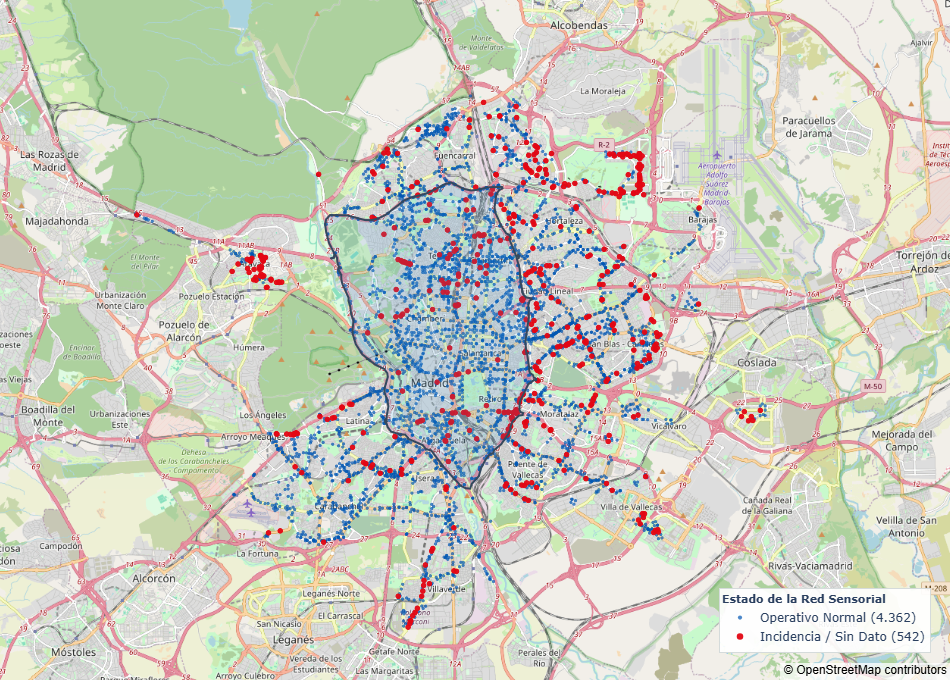

In [5]:
print("====== GENERANDO MAPA CARTOGRÁFICO DE SENSORES DE TRÁFICO (OPENSTREETMAP + M-30) ======\n")

# 1. Ordenar para dibujar primero operativos (base) y encima incidencias (primer plano)
df_mapa = df_trafico.copy()
df_mapa['es_incidencia'] = df_mapa['error_sensor'] != 'N'
df_mapa = df_mapa.sort_values('es_incidencia', ascending=True)

df_mapa['Estado Técnico'] = np.where(
    df_mapa['error_sensor'] == 'N',
    'Operativo Normal (4.362)',
    'Incidencia / Sin Dato (542)'
)
df_mapa['descripcion_limpia'] = df_mapa['descripcion'].fillna('Sin descripción vial')

gdf_m30_oficial = gpd.read_file('../data/processed/m30_oficial.geojson')

centro_lat = df_mapa['lat'].mean()
centro_lon = df_mapa['lon'].mean()

# 2. Construcción de la figura sobre OpenStreetMap con zoom completo (10.6)
fig = px.scatter_map(
    df_mapa,
    lat="lat",
    lon="lon",
    color="Estado Técnico",
    color_discrete_map={
        'Operativo Normal (4.362)': '#0056B3',      # Azul EMT
        'Incidencia / Sin Dato (542)': '#E30613'    # Rojo EMT
    },
    hover_name="idelem",
    hover_data={
        "lat": False,
        "lon": False,
        "descripcion_limpia": True,
        "carga": True,
        "Estado Técnico": False
    },
    zoom=10.6,
    height=780
)

# Jerarquía visual equilibrada para que no se empasten sobre el callejero
fig.for_each_trace(
    lambda t: t.update(marker=dict(size=4.2, opacity=0.70))
    if "Operativo" in t.name
    else t.update(marker=dict(size=6.5, opacity=0.95))
)

# 3. Inyección geoespacial oficial del perímetro de la M-30
capa_relleno = {
    "sourcetype": "geojson",
    "source": gdf_m30_oficial.__geo_interface__,
    "type": "fill",
    "color": "rgba(52, 152, 219, 0.15)"
}

capa_borde = {
    "sourcetype": "geojson",
    "source": gdf_m30_oficial.__geo_interface__,
    "type": "line",
    "color": "#34495E",
    "line": {"width": 2.0}
}

fig.update_layout(
    map_style="open-street-map",
    map_center={"lat": centro_lat, "lon": centro_lon},
    map_layers=[capa_relleno, capa_borde],
    margin={"r": 0, "t": 0, "l": 0, "b": 0},
    autosize=True,
    legend=dict(
        title="Estado de la Red Sensorial",
        title_font=dict(size=11, weight='bold'),
        yanchor="bottom", y=0.04,
        xanchor="right", x=0.98,
        bgcolor="rgba(255, 255, 255, 0.92)",
        bordercolor="#D5DBDB", borderwidth=1
    )
)

# 4. Exportación del artefacto interactivo HTML y visualización estática ligera en PNG
os.makedirs("../reports", exist_ok=True)
ruta_html = "../reports/mapa_sensores_trafico.html"
ruta_png = "../reports/mapa_sensores_trafico.png"

fig.write_html(ruta_html, include_plotlyjs="cdn")
fig.write_image(ruta_png, width=950, height=680, scale=1)

display(Image(filename=ruta_png))


> **🗺️ Exploración Interactiva:** Acceso a la versión navegable con zoom dinámico y fichas emergentes por estación de medida directamente en el navegador a través de **[Mapa Interactivo de Sensores de Tráfico (`GitHub Pages`)](https://herasduarte.github.io/Proyecto_puntualidad_emt/reports/mapa_sensores_trafico.html)**.

> **📌 Diagnóstico Cartográfico de la Red Sensorial:**
> * **Concentración en la Almendra Central (M-30):** La densidad de espiras electromagnéticas operativas (`4.362` estaciones en azul) es máxima en el interior de la M-30 y los grandes ejes radiales (Castellana, Alcalá, A-2, A-5, A-42), garantizando una cobertura directa del **99,81%** de las paradas EMT centrales en un radio de 500 metros.
>
> * **Patrón Agrupado de las Incidencias (`542` estaciones en rojo):** Los sensores fuera de servicio no se distribuyen de forma aleatoria, sino agrupados por corredores específicos (destacando un tramo continuo en el entorno de la **A-2 / Campo de las Naciones** y enlaces perimetrales). El filtrado previo por `error_sensor == 'N'` evita que las paradas situadas junto a esos tramos en mantenimiento hereden valores corruptos, reasignándolas automáticamente a los sensores operativos adyacentes.

#### 3.2. Contraste Cuantitativo de Carga Vial y Nivel de Servicio por Ámbito Territorial (M-30)

Se compara la distribución de la **carga vial ponderada (`trafico_carga_entorno`)** y la frecuencia del **peor nivel de servicio detectado en el entorno (`trafico_nivel_servicio_max`)** entre las paradas ubicadas en el interior de la **M-30** y las de la periferia exterior.

====== GENERANDO PANEL VISUAL 3.2: DENSIDAD DE CARGA VIAL Y ESTADO SEMAFÓRICO (M-30) ======



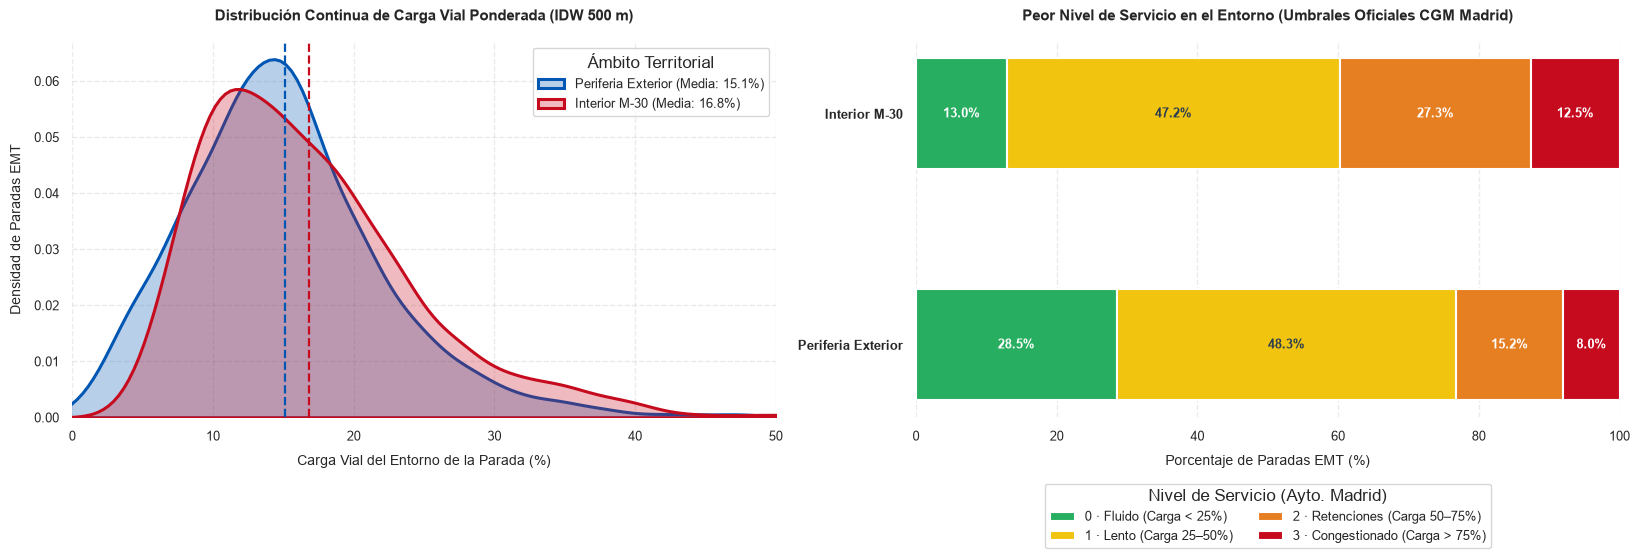

In [6]:
print("====== GENERANDO PANEL VISUAL 3.2: DENSIDAD DE CARGA VIAL Y ESTADO SEMAFÓRICO (M-30) ======\n")

df_validas_traf = df_cruce_paradas.dropna(subset=['trafico_carga_entorno']).copy()
df_validas_traf['Zona'] = df_validas_traf['en_alta_densidad_real'].map({
    True: 'Interior M-30',
    False: 'Periferia Exterior'
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 5.8))

# --- PANEL IZQUIERDO: CURVAS DE DENSIDAD (KDE) SUPERPUESTAS DE CARGA VIAL ---
paleta_zonas = {'Interior M-30': '#C60B1E', 'Periferia Exterior': '#0056B3'}

for zona in ['Periferia Exterior', 'Interior M-30']:
    sub = df_validas_traf[df_validas_traf['Zona'] == zona]['trafico_carga_entorno']
    media_z = sub.mean()
    color_z = paleta_zonas[zona]

    sns.kdeplot(
        data=sub,
        fill=True,
        alpha=0.28,
        linewidth=2.2,
        color=color_z,
        label=f"{zona} (Media: {media_z:.1f}%)",
        ax=ax1
    )
    ax1.axvline(media_z, color=color_z, linestyle='--', linewidth=1.6)

ax1.set_title("Distribución Continua de Carga Vial Ponderada (IDW 500 m)", fontsize=11, weight='bold', pad=15)
ax1.set_xlabel("Carga Vial del Entorno de la Parada (%)", fontsize=10, labelpad=8)
ax1.set_ylabel("Densidad de Paradas EMT", fontsize=10, labelpad=8)
ax1.set_xlim(0, 50)
ax1.legend(title="Ámbito Territorial", frameon=True, facecolor='white', fontsize=9.5)
ax1.yaxis.grid(True)
ax1.xaxis.grid(True)

# --- PANEL DERECHO: COMPOSICIÓN HORIZONTAL 100% DEL NIVEL DE SERVICIO ---
orden_ns = [0.0, 1.0, 2.0, 3.0]
etiquetas_ns_detalle = {
    0.0: '0 · Fluido (Carga < 25%)',
    1.0: '1 · Lento (Carga 25–50%)',
    2.0: '2 · Retenciones (Carga 50–75%)',
    3.0: '3 · Congestionado (Carga > 75%)'
}
colores_ns = ['#27AE60', '#F1C40F', '#E67E22', '#C60B1E']

tabla_pct = (
    pd.crosstab(
        df_validas_traf['Zona'],
        df_validas_traf['trafico_nivel_servicio_max'],
        normalize='index'
    )
    .reindex(index=['Periferia Exterior', 'Interior M-30'], columns=orden_ns, fill_value=0.0) * 100.0
)

izquierda = np.zeros(len(tabla_pct))
y_pos = np.arange(len(tabla_pct))

for idx_ns, col_ns in enumerate(orden_ns):
    valores = tabla_pct[col_ns].values
    barras = ax2.barh(
        y_pos,
        valores,
        left=izquierda,
        height=0.48,
        color=colores_ns[idx_ns],
        edgecolor='white',
        linewidth=1.5,
        label=etiquetas_ns_detalle[col_ns]
    )
    for j, val in enumerate(valores):
        if val >= 7.0:
            color_txt = 'white' if idx_ns in (0, 2, 3) else '#2C3E50'
            ax2.text(
                izquierda[j] + val / 2.0,
                y_pos[j],
                f"{val:.1f}%",
                ha='center', va='center',
                fontsize=9.5, weight='bold', color=color_txt
            )
    izquierda += valores

ax2.set_yticks(y_pos)
ax2.set_yticklabels(['Periferia Exterior', 'Interior M-30'], fontsize=10, weight='bold')
ax2.set_xlim(0, 100)
ax2.set_xlabel("Porcentaje de Paradas EMT (%)", fontsize=10, labelpad=8)
ax2.set_title("Peor Nivel de Servicio en el Entorno (Umbrales Oficiales CGM Madrid)", fontsize=11, weight='bold', pad=15)
ax2.legend(
    title="Nivel de Servicio (Ayto. Madrid)",
    loc='upper center',
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    frameon=True,
    facecolor='white',
    fontsize=9
)
ax2.xaxis.grid(True)
ax2.yaxis.grid(False)

for ax_canvas in [ax1, ax2]:
    ax_canvas.tick_params(axis='both', labelsize=9.5)
    sns.despine(ax=ax_canvas, top=True, right=True, left=True, bottom=True)

plt.tight_layout()
plt.show()



> **📌 Lectura Analítica del Contraste Territorial (M-30):**
> * **Desplazamiento de la Carga Vial en la Almendra Central:** La distribución continua de densidad (panel izquierdo) muestra cómo la curva del **Interior de la M-30** se desplaza hacia valores superiores de saturación respecto a la **Periferia Exterior** (alcanzando una carga media ponderada del **16,8%** frente al **15,1%** periférico, incluso en franja nocturna de captura a las `21:50h`), con mayor peso en la cola de cargas entre el `20%` y el `45%`.
>
> * **Contraste en la Composición del Nivel de Servicio:** Según los umbrales oficiales del Centro de Gestión de la Movilidad (CGM) de Madrid (panel derecho), en el **Interior de la M-30** solo el **13,0%** de las paradas disfruta de tráfico completamente fluido (*Nivel 0 · Carga < 25%*), frente al **28,5%** en la **Periferia Exterior**. Por el contrario, los episodios de retención y saturación (*Niveles 2 y 3*) afectan al **39,9%** de las paradas centrales (**27,4%** en *Retenciones* y **12,5%** en *Congestionado*), casi duplicando el **23,2%** registrado en el exterior de la M-30 (**15,2%** y **8,0%**, respectivamente), mientras que el régimen *Lento* (*Nivel 1*) representa una proporción similar en ambos ámbitos (**47,2%** interior y **48,3%** exterior).

## 📋 Conclusiones Ejecutivas y Preparación para el Modelo 2 (*Contexto Vial*)

1. **Saneamiento Técnico Certificado:** Del total de **4.904 puntos de medida** publicados por el Ayuntamiento de Madrid (`informo.madrid.es`), el **88,95% (`4.362` estaciones)** opera en estado normal (`error_sensor == 'N'`). El filtrado previo elimina los **542 sensores** con incidencia técnica o descripción nula, así como los valores centinela negativos (`-1`).

2. **Cobertura Geodésica del `98,07%` de la Red EMT:** La estrategia de ponderación por inversa de la distancia (*IDW*) con radio principal de **500 metros** y respaldo hasta **1.000 metros** vincula mediciones reales de tráfico a **4.833 de las 4.928 paradas EMT** (**100,00%** en el interior de la M-30 con una distancia mediana de **59,2 m** al sensor más próximo, y **97,15%** en la periferia exterior).

3. **Selección Óptima de Predictores Viales:** Debido a que `velocidad_trafico` presenta un **93,66% de valores nulos** (restringida a túneles de la M-30), se seleccionan como variables universales de superficie **`trafico_carga_entorno`**, **`trafico_ocupacion_entorno`**, **`trafico_intensidad_entorno`**, **`trafico_nivel_servicio_max`**, **`num_sensores_500m`**, **`distancia_sensor_mas_cercano_m`** y **`tiene_cobertura_trafico_500m`**.

4. **Paso a Producción (`src/sensores_trafico.py`):** La lógica de descarga, saneamiento XML, transformación de coordenadas (`EPSG:25830` → `WGS84`) y cálculo de la matriz espacial *IDW* queda validada para encapsularse en el módulo reutilizable **`src/sensores_trafico.py`** y documentarse en **`docs/10_sensores_trafico_Dict.md`**.

---
> **Atribución de Fuente de Datos:** *Powered by [EMT de Madrid](http://www.emtmadrid.es)* (Portal de Datos Abiertos MobilityLabs / Ayuntamiento de Madrid).